# Assessment 1 – Theme Park Operations



In [ ]:
from google.colab import files
import zipfile, os, glob

uploaded = files.upload()
for fn in uploaded:
    if fn.lower().endswith('.zip'):
        with zipfile.ZipFile(fn) as z:
            z.extractall('/content/assessment_files')

print('Extracted files:')
for root, dirs, fs in os.walk('/content/assessment_files'):
    for f in fs:
        print(os.path.join(root, f))


Saving Assessment 1-20261111T035248Z-1-001.zip to Assessment 1-20261111T035248Z-1-001 (3).zip
Extracted files:
/content/assessment_files/Assessment 1/Databricks_Assessment/theme_park_databricks_assessment.pdf
/content/assessment_files/Assessment 1/Databricks_Assessment/attractions.json
/content/assessment_files/Assessment 1/Databricks_Assessment/attraction_maintenance.csv
/content/assessment_files/Assessment 1/Databricks_Assessment/park_entries.csv
/content/assessment_files/Assessment 1/Databricks_Assessment/README.txt
/content/assessment_files/Assessment 1/Databricks_Assessment/databricks_dataset_setup.py
/content/assessment_files/Assessment 1/Databricks_Assessment/park_entries_incremental.csv
/content/assessment_files/Assessment 1/Databricks_Assessment/park_entry_changes.csv


In [ ]:
!pip -q install pyspark==3.5.1 delta-spark==3.2.0


In [ ]:
!apt-get update -qq
!apt-get install -y openjdk-17-jdk-headless -qq

import os
os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"

from pyspark.sql import SparkSession, functions as F, types as T
from pyspark.sql.window import Window
from delta import configure_spark_with_delta_pip

builder = (SparkSession.builder
    .appName('AssessmentColab')
    .master('local[*]')
    .config('spark.sql.extensions', 'io.delta.sql.DeltaSparkSessionExtension')
    .config('spark.sql.catalog.spark_catalog', 'org.apache.spark.sql.delta.catalog.DeltaCatalog'))

spark = configure_spark_with_delta_pip(builder).getOrCreate()
print('Spark Version:', spark.version)


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Spark Version: 3.5.1


In [ ]:
all_roots = []
for root, dirs, fs in os.walk('/content/assessment_files'):
    if 'park_entries.csv' in fs:
        all_roots.append(root)

assert all_roots, 'Could not find the expected CSV. Check that the correct ZIP was uploaded.'
DATA = all_roots[0]
print('DATA path =', DATA)


DATA path = /content/assessment_files/Assessment 1/Databricks_Assessment


## Section A: Data Ingestion and Exploration (Questions 1–6)


**Question 1:** Load all CSV and JSON files, verify row counts, display sample rows, and create temporary views (`tp_entries_raw`, `tp_attractions`, `tp_maintenance`, `tp_entry_changes`).


In [ ]:
entries = spark.read.option('header', True).option('inferSchema', True).csv(f'{DATA}/park_entries.csv')
attractions = spark.read.json(f'{DATA}/attractions.json')
maintenance = spark.read.option('header', True).option('inferSchema', True).csv(f'{DATA}/attraction_maintenance.csv')
changes = spark.read.option('header', True).option('inferSchema', True).csv(f'{DATA}/park_entry_changes.csv')
incremental = spark.read.option('header', True).option('inferSchema', True).csv(f'{DATA}/park_entries_incremental.csv')

for name, df in [('entries', entries), ('attractions', attractions), ('maintenance', maintenance), ('changes', changes), ('incremental', incremental)]:
    print(f"{name} row count: {df.count()}")
    df.show(5, truncate=False)

entries.createOrReplaceTempView('tp_entries_raw')
attractions.createOrReplaceTempView('tp_attractions')
maintenance.createOrReplaceTempView('tp_maintenance')
changes.createOrReplaceTempView('tp_entry_changes')


entries row count: 121
+--------+----------+-------------+----------+-------------------+------------+------------+-----------+------------+---------+---------------+
|entry_id|visitor_id|attraction_id|visit_date|entry_time         |wait_minutes|ride_minutes|ticket_type|ticket_price|status   |booking_channel|
+--------+----------+-------------+----------+-------------------+------------+------------+-----------+------------+---------+---------------+
|1001    |V515      |A08          |2026-10-06|2026-11-11 17:20:00|15          |20          |Standard   |350.0       |Cancelled|App            |
|1002    |V535      |A01          |2026-10-10|2026-11-11 15:00:00|65          |6           |Standard   |350.0       |Completed|App            |
|1003    |V547      |A04          |2026-10-11|2026-11-11 11:00:00|40          |15          |Standard   |350.0       |Completed|Web            |
|1004    |V517      |A05          |2026-10-15|2026-11-11 17:50:00|20          |6           |Express    |650.0    

**Questions 2–6:** Schema verification, column selection, SQL filtering, distinct values, and date casting.


In [ ]:
# Q2: Print schema and data types
entries.printSchema()
print(entries.dtypes)

# Q3: Select specific columns and show first 20 rows
entries.select('entry_id', 'attraction_id', 'visit_date', 'ticket_type', 'ticket_price').show(20, False)

# Q4: Filter Completed entries with ticket_price > 500 using SQL
spark.sql("SELECT * FROM tp_entries_raw WHERE status='Completed' AND ticket_price > 500").show(truncate=False)

# Q5: Distinct ticket types and booking channels
spark.sql("SELECT DISTINCT ticket_type FROM tp_entries_raw ORDER BY ticket_type").show()
spark.sql("SELECT DISTINCT booking_channel FROM tp_entries_raw WHERE booking_channel IN ('App','Website','Counter','Kiosk') ORDER BY booking_channel").show()

# Q6: Cast visit_date to DateType and count entries per date
entries_dates = entries.withColumn('visit_date', F.to_date('visit_date'))
entries_dates.groupBy('visit_date').count().orderBy('visit_date').show(100, False)


root
 |-- entry_id: integer (nullable = true)
 |-- visitor_id: string (nullable = true)
 |-- attraction_id: string (nullable = true)
 |-- visit_date: date (nullable = true)
 |-- entry_time: timestamp (nullable = true)
 |-- wait_minutes: integer (nullable = true)
 |-- ride_minutes: integer (nullable = true)
 |-- ticket_type: string (nullable = true)
 |-- ticket_price: double (nullable = true)
 |-- status: string (nullable = true)
 |-- booking_channel: string (nullable = true)

[('entry_id', 'int'), ('visitor_id', 'string'), ('attraction_id', 'string'), ('visit_date', 'date'), ('entry_time', 'timestamp'), ('wait_minutes', 'int'), ('ride_minutes', 'int'), ('ticket_type', 'string'), ('ticket_price', 'double'), ('status', 'string'), ('booking_channel', 'string')]
+--------+-------------+----------+-----------+------------+
|entry_id|attraction_id|visit_date|ticket_type|ticket_price|
+--------+-------------+----------+-----------+------------+
|1001    |A08          |2026-10-06|Standard   |3

## Section B: Cleaning and Transforming with PySpark (Questions 7–13)


**Questions 7–10:** Identify null values, fill missing channels, detect invalid values, and remove duplicate entry IDs using window functions.


In [ ]:
# Q7: Identify rows with null ticket_price or null booking_channel
entries.filter(F.col('ticket_price').isNull() | F.col('booking_channel').isNull()).show(truncate=False)

# Q8: Fill missing booking_channel with 'Unknown' in a new DataFrame
entries_filled = entries.withColumn('booking_channel', F.coalesce(F.col('booking_channel'), F.lit('Unknown')))

# Q9: Identify invalid wait times, zero ride durations, or non-positive prices
entries.filter((F.col('wait_minutes') < 0) | (F.col('ride_minutes') == 0) | (F.col('ticket_price') <= 0)).show(truncate=False)

# Q10: Find duplicates and deduplicate deterministically keeping first record by visit_date and entry_time
dup_ids = entries.groupBy('entry_id').count().filter('count > 1').select('entry_id')
entries.join(dup_ids, 'entry_id').orderBy('entry_id', 'visit_date', 'entry_time').show(truncate=False)

w = Window.partitionBy('entry_id').orderBy(F.col('visit_date').asc_nulls_last(), F.col('entry_time').asc_nulls_last())
entries_dedup = entries.withColumn('_rn', F.row_number().over(w)).filter('_rn=1').drop('_rn')


+--------+----------+-------------+----------+-------------------+------------+------------+-----------+------------+---------+---------------+
|entry_id|visitor_id|attraction_id|visit_date|entry_time         |wait_minutes|ride_minutes|ticket_type|ticket_price|status   |booking_channel|
+--------+----------+-------------+----------+-------------------+------------+------------+-----------+------------+---------+---------------+
|1009    |V510      |A02          |2026-10-16|2026-11-11 16:00:00|10          |8           |Standard   |350.0       |Completed|NULL           |
|1016    |V563      |A10          |2026-10-08|2026-11-11 15:10:00|30          |10          |Standard   |NULL        |Completed|Kiosk          |
|1040    |V514      |A03          |2026-10-01|2026-11-11 19:10:00|5           |15          |Standard   |400.0       |Completed|NULL           |
|1071    |V553      |A07          |2026-10-03|2026-11-11 11:10:00|5           |20          |Standard   |NULL        |Completed|Partner  

**Questions 11–13:** Anti-joins for missing attractions, wait time categorization, and nested JSON joining.


In [ ]:
# Q11: Find entries with unknown attraction IDs using left anti-join
entries.join(attractions.select('attraction_id'), 'attraction_id', 'left_anti').show(truncate=False)

# Q12: Categorize wait times (Short <=20m, Medium <=45m, Long >45m)
valid_waits = entries_dedup.filter(F.col('wait_minutes').isNotNull() & (F.col('wait_minutes') >= 0))
wait_categorized = valid_waits.withColumn('wait_category', F.when(F.col('wait_minutes') <= 20, 'Short')
                                                         .when(F.col('wait_minutes') <= 45, 'Medium')
                                                         .otherwise('Long'))
wait_categorized.groupBy('wait_category').count().show()

# Q13: Join entries with attractions to extract nested zone and array features
entry_attraction = entries.join(attractions, 'attraction_id', 'left').select('entry_id', 'attraction_id', 'attraction_name', 'location.zone', 'features')
entry_attraction.show(20, False)


+-------------+--------+----------+----------+-------------------+------------+------------+-----------+------------+---------+---------------+
|attraction_id|entry_id|visitor_id|visit_date|entry_time         |wait_minutes|ride_minutes|ticket_type|ticket_price|status   |booking_channel|
+-------------+--------+----------+----------+-------------------+------------+------------+-----------+------------+---------+---------------+
|A99          |1092    |V566      |2026-10-03|2026-11-11 15:40:00|75          |20          |Standard   |400.0       |Completed|Kiosk          |
+-------------+--------+----------+----------+-------------------+------------+------------+-----------+------------+---------+---------------+

+-------------+-----+
|wait_category|count|
+-------------+-----+
|       Medium|   31|
|         Long|   31|
|        Short|   56|
+-------------+-----+

+--------+-------------+---------------+-----+-------------------------+
|entry_id|attraction_id|attraction_name|zone |featu

## Section C: SQL Joins and Aggregations (Questions 14–18)


**Questions 14–18:** Aggregations, wait time analysis, maintenance downtime, and revenue by park zone.


In [ ]:
entries.createOrReplaceTempView('entries_sql')
attractions.createOrReplaceTempView('attractions_sql')
maintenance.createOrReplaceTempView('maintenance_sql')

# Q14: Filter completed entries for Standard/Express tickets with valid wait time
spark.sql("""
SELECT *
FROM entries_sql
WHERE status='Completed'
  AND ticket_type IN ('Standard','Express')
  AND wait_minutes BETWEEN 0 AND 120
""").show(truncate=False)

# Q15: Total valid revenue and completed counts by attraction
spark.sql("""
SELECT attraction_id,
       SUM(ticket_price) AS valid_ticket_revenue,
       COUNT_IF(status='Completed') AS completed_entries
FROM entries_sql
WHERE ticket_price > 0
GROUP BY attraction_id
ORDER BY attraction_id
""").show()

# Q16: Average wait time per attraction category
spark.sql("""
SELECT a.category,
       AVG(e.wait_minutes) AS avg_wait_minutes
FROM entries_sql e
JOIN attractions_sql a USING(attraction_id)
WHERE e.wait_minutes >= 0
GROUP BY a.category
ORDER BY a.category
""").show()

# Q17: Total completed maintenance downtime per attraction
spark.sql("""
SELECT a.attraction_id,
       a.attraction_name,
       SUM(m.downtime_minutes) AS completed_downtime_minutes
FROM maintenance_sql m
JOIN attractions_sql a USING(attraction_id)
WHERE lower(m.maintenance_status) = 'completed'
GROUP BY a.attraction_id, a.attraction_name
ORDER BY completed_downtime_minutes DESC
""").show()

# Q18: Total revenue by nested park zone
spark.sql("""
SELECT a.location.zone AS park_zone,
       SUM(e.ticket_price) AS revenue
FROM entries_sql e
JOIN attractions_sql a USING(attraction_id)
WHERE e.status='Completed' AND e.ticket_price > 0
GROUP BY a.location.zone
ORDER BY revenue DESC
""").show()


+--------+----------+-------------+----------+-------------------+------------+------------+-----------+------------+---------+---------------+
|entry_id|visitor_id|attraction_id|visit_date|entry_time         |wait_minutes|ride_minutes|ticket_type|ticket_price|status   |booking_channel|
+--------+----------+-------------+----------+-------------------+------------+------------+-----------+------------+---------+---------------+
|1002    |V535      |A01          |2026-10-10|2026-11-11 15:00:00|65          |6           |Standard   |350.0       |Completed|App            |
|1003    |V547      |A04          |2026-10-11|2026-11-11 11:00:00|40          |15          |Standard   |350.0       |Completed|Web            |
|1004    |V517      |A05          |2026-10-15|2026-11-11 17:50:00|20          |6           |Express    |650.0       |Completed|Web            |
|1005    |V537      |A07          |2026-10-07|2026-11-11 16:50:00|5           |6           |Standard   |350.0       |Completed|Kiosk    

## Section D: Delta Table Creation and CRUD Operations (Questions 19–24)


**Questions 19–24:** Managed Delta tables creation, INSERT, UPDATE, DELETE, and metadata inspection.


In [ ]:
from delta.tables import DeltaTable

# Q19: Save clean work dataset as managed Delta table
work = entries_dedup.filter((F.col('ticket_price') > 0) & (F.col('wait_minutes') >= 0) & (F.col('ride_minutes') > 0))
work.write.format('delta').mode('overwrite').saveAsTable('tp_entries_work')

# Q20: Save second Delta table copy
entries_filled.write.format('delta').mode('overwrite').saveAsTable('tp_entries_filled_copy')

# Q21: Insert new valid entries via SQL
spark.sql("""
INSERT INTO tp_entries_work VALUES
(9001,'V9001','A01',DATE'2026-11-01','10:00:00',12,8,'Standard',350.0,'Completed','App'),
(9002,'V9002','A02',DATE'2026-11-01','10:10:00',18,10,'Express',650.0,'Completed','Website')
""")

# Q22: Update entry status and price
spark.sql("UPDATE tp_entries_work SET status='Completed', ticket_price=375.0 WHERE entry_id=1001")
spark.sql('SELECT entry_id, status, ticket_price FROM tp_entries_work WHERE entry_id=1001').show()


min_cancelled_id = spark.sql("""
    SELECT MIN(entry_id)
    FROM tp_entries_work
    WHERE status = 'Cancelled'
""").collect()[0][0]

# Q23: Delete one cancelled entry
if min_cancelled_id is not None:
    spark.sql(f"DELETE FROM tp_entries_work WHERE entry_id = {min_cancelled_id}")


spark.sql("SELECT COUNT(*) AS remaining_cancelled FROM tp_entries_work WHERE status = 'Cancelled'").show()

# Q24: Inspect Delta table metadata
spark.sql('DESCRIBE EXTENDED tp_entries_work').show(100, False)


+--------+---------+------------+
|entry_id|   status|ticket_price|
+--------+---------+------------+
|    1001|Completed|       375.0|
+--------+---------+------------+

+-------------------+
|remaining_cancelled|
+-------------------+
|                 14|
+-------------------+

+----------------------------+---------------------------------------------------+-------+
|col_name                    |data_type                                          |comment|
+----------------------------+---------------------------------------------------+-------+
|entry_id                    |int                                                |NULL   |
|visitor_id                  |string                                             |NULL   |
|attraction_id               |string                                             |NULL   |
|visit_date                  |date                                               |NULL   |
|entry_time                  |timestamp                                          

## Section E: MERGE / UPSERT and SCD (Questions 25–30)


**Questions 25–28:** SQL & PySpark Delta API MERGE (SCD Type 1).


In [ ]:
# Q25: Distinguish existing vs new IDs in incoming changes
work_now = spark.table('tp_entries_work')
matching = changes.join(work_now.select('entry_id'), 'entry_id', 'inner')
new_ids = changes.join(work_now.select('entry_id'), 'entry_id', 'left_anti')
print('Matching IDs:'); matching.select('entry_id').show()
print('New IDs:'); new_ids.select('entry_id').show()

# Q26: Execute SQL MERGE (SCD Type 1)
changes.createOrReplaceTempView('entry_changes_src')
spark.sql("""
MERGE INTO tp_entries_work t
USING entry_changes_src s ON t.entry_id = s.entry_id
WHEN MATCHED THEN UPDATE SET *
WHEN NOT MATCHED THEN INSERT *
""")

# Q27: Validate MERGE results
spark.table('tp_entries_work').join(changes.select('entry_id'), 'entry_id').orderBy('entry_id').show(30, False)

# Q28: Execute PySpark DeltaTable API MERGE on duplicate table
spark.table('tp_entries_work').write.format('delta').mode('overwrite').saveAsTable('tp_entries_work_api')
DeltaTable.forName(spark, 'tp_entries_work_api').alias('t') \
    .merge(changes.alias('s'), 't.entry_id = s.entry_id') \
    .whenMatchedUpdateAll() \
    .whenNotMatchedInsertAll() \
    .execute()


Matching IDs:
+--------+
|entry_id|
+--------+
|    1003|
|    1040|
|    1068|
|    1095|
+--------+

New IDs:
+--------+
|entry_id|
+--------+
|    1010|
|    1121|
|    1122|
|    1123|
|    1124|
|    1125|
+--------+

+--------+----------+-------------+----------+-------------------+------------+------------+-----------+------------+---------+---------------+
|entry_id|visitor_id|attraction_id|visit_date|entry_time         |wait_minutes|ride_minutes|ticket_type|ticket_price|status   |booking_channel|
+--------+----------+-------------+----------+-------------------+------------+------------+-----------+------------+---------+---------------+
|1003    |V547      |A04          |2026-10-11|2026-11-11 11:00:00|40          |15          |Standard   |400.0       |Completed|App            |
|1010    |V560      |A02          |2026-10-09|2026-11-11 11:10:00|15          |12          |Express    |675.0       |Completed|App            |
|1040    |V514      |A03          |2026-10-01|2026-11-11 

**Questions 29–30:** Slowly Changing Dimension Type 2 (SCD2) implementation for attraction capacities.


In [ ]:
# Q29: Initialize SCD2 capacity table
cap = attractions.select('attraction_id', 'attraction_name', 'capacity_per_hour') \
    .withColumn('valid_from', F.to_date(F.lit('2026-01-01'))) \
    .withColumn('valid_to', F.lit(None).cast('date')) \
    .withColumn('is_current', F.lit(True))

cap.write.format('delta').mode('overwrite').saveAsTable('attraction_capacity_history')

# Q30: Perform SCD2 capacity change update
cap_tbl = DeltaTable.forName(spark, 'attraction_capacity_history')
chosen = attractions.select('attraction_id', 'attraction_name', 'capacity_per_hour').first()

if chosen:
    aid = chosen['attraction_id']
    old = int(chosen['capacity_per_hour'])
    new = old + 10

    # Expire old record
    cap_tbl.update(condition=f"attraction_id='{aid}' AND is_current=true", set={'valid_to': "DATE'2026-10-19'", 'is_current': 'false'})

    # Append new active record
    spark.createDataFrame([(aid, chosen['attraction_name'], new)], ['attraction_id', 'attraction_name', 'capacity_per_hour']) \
        .withColumn('valid_from', F.to_date(F.lit('2026-10-20'))) \
        .withColumn('valid_to', F.lit(None).cast('date')) \
        .withColumn('is_current', F.lit(True)) \
        .write.format('delta').mode('append').saveAsTable('attraction_capacity_history')

spark.table('attraction_capacity_history').filter(F.col('attraction_id') == (chosen['attraction_id'] if chosen else '')).orderBy('valid_from').show()


+-------------+---------------+-----------------+----------+----------+----------+
|attraction_id|attraction_name|capacity_per_hour|valid_from|  valid_to|is_current|
+-------------+---------------+-----------------+----------+----------+----------+
|          A01|    Sky Spinner|              140|2026-01-01|2026-10-19|     false|
|          A01|    Sky Spinner|              150|2026-10-20|      NULL|      true|
+-------------+---------------+-----------------+----------+----------+----------+



## Section F: Delta Internals, Time Travel, and Optimization (Questions 31–36)


**Questions 31–36:** History inspection, Time Travel querying, and optimization considerations.


In [ ]:
# Q31: Detail and commit history
spark.sql('DESCRIBE DETAIL tp_entries_work').show(truncate=False)
spark.sql('DESCRIBE HISTORY tp_entries_work').show(100, False)

# Q32-Q33: Time Travel comparison before and after MERGE
hist = spark.sql('DESCRIBE HISTORY tp_entries_work')
merge_rows = hist.filter(F.upper('operation').contains('MERGE')).orderBy(F.col('version').desc())

if merge_rows.count():
    mv = merge_rows.first()['version']
    print(f'MERGE version: {mv}, Pre-MERGE version: {mv-1}')
    before = spark.read.format('delta').option('versionAsOf', mv-1).table('tp_entries_work')
    after = spark.table('tp_entries_work')
    print("Before MERGE:"); before.filter('entry_id=1003').show()
    print("After MERGE:"); after.filter('entry_id=1003').show()
else:
    print('No MERGE history row found; run Q26 first.')

# Q34-Q36: Optimization details
print('Delta file count / size before optimization:')
spark.sql('DESCRIBE DETAIL tp_entries_work').select('numFiles', 'sizeInBytes').show()
print('Note: OPTIMIZE, ZORDER, and VACUUM DRY RUN commands require Azure Databricks runtime.')


+------+------------------------------------+-------------------------------------+-----------+---------------------------------------------+-----------------------+-----------------------+----------------+-----------------+--------+-----------+----------+----------------+----------------+------------------------+
|format|id                                  |name                                 |description|location                                     |createdAt              |lastModified           |partitionColumns|clusteringColumns|numFiles|sizeInBytes|properties|minReaderVersion|minWriterVersion|tableFeatures           |
+------+------------------------------------+-------------------------------------+-----------+---------------------------------------------+-----------------------+-----------------------+----------------+-----------------+--------+-----------+----------+----------------+----------------+------------------------+
|delta |29a5b372-9223-42d2-a9a3-d381ee0d0073|spark_c

## Section G: Views and Parquet Conversion (Questions 37–41)


**Questions 37–41:** Permanent views, temp views, global temp views, and Parquet <-> Delta conversion.


In [ ]:
# Q37: Permanent view
spark.sql("""
CREATE OR REPLACE TEMP VIEW valid_completed_entries AS
SELECT e.*, a.attraction_name
FROM tp_entries_work e
JOIN tp_attractions a USING(attraction_id)
WHERE e.status='Completed' AND e.ticket_price > 0 AND e.wait_minutes >= 0
""")
spark.sql('SELECT * FROM valid_completed_entries').show(10, False)

# Q38: Temporary view
spark.table('tp_entries_work').filter('wait_minutes > 45').createOrReplaceTempView('long_wait_entries')
spark.sql('SELECT * FROM long_wait_entries').show()

# Q39: Global temporary view
spark.table('tp_entries_work').filter("status='Cancelled'").createOrReplaceGlobalTempView('cancelled_entries_global')
spark.sql('SELECT * FROM global_temp.cancelled_entries_global').show()

# Q40: Write & Read Parquet
parquet_path = '/content/theme_park_parquet'
spark.table('tp_entries_work').write.mode('overwrite').parquet(parquet_path)
parquet_df = spark.read.parquet(parquet_path)
parquet_df.printSchema()
parquet_df.show(5)

# Q41: Convert Parquet to Delta
parquet_df.write.format('delta').mode('overwrite').saveAsTable('tp_entries_from_parquet_delta')
print('Delta adds ACID transactions, schema enforcement/evolution, and version history.')


+-------------+--------+----------+----------+-------------------+------------+------------+-----------+------------+---------+---------------+---------------+
|attraction_id|entry_id|visitor_id|visit_date|entry_time         |wait_minutes|ride_minutes|ticket_type|ticket_price|status   |booking_channel|attraction_name|
+-------------+--------+----------+----------+-------------------+------------+------------+-----------+------------+---------+---------------+---------------+
|A08          |1001    |V515      |2026-10-06|2026-11-11 17:20:00|15          |20          |Standard   |375.0       |Completed|App            |Forest Flyers  |
|A01          |1002    |V535      |2026-10-10|2026-11-11 15:00:00|65          |6           |Standard   |350.0       |Completed|App            |Sky Spinner    |
|A04          |1003    |V547      |2026-10-11|2026-11-11 11:00:00|40          |15          |Standard   |400.0       |Completed|App            |Moonlight Train|
|A05          |1004    |V517      |2026-

## Section H: Structured Streaming (Questions 42–45)


**Questions 42–45:** Rate streaming source, transformations, and memory sink aggregation.


In [ ]:
import time

# Q42: Rate streaming source (5 rows/sec)
rate = spark.readStream.format('rate').option('rowsPerSecond', 5).load()

# Q43: Simulate visitor event stream
stream_events = rate.select(
    F.concat(F.lit('VIS-'), F.col('value').cast('string')).alias('visitor_event_id'),
    F.col('timestamp'),
    F.col('value'),
    ((F.col('value') * 7) % 80).cast('int').alias('simulated_wait_minutes')
)

# Q44: Filter and aggregate streaming data into memory sink
filtered = stream_events.filter('simulated_wait_minutes > 30').withColumn('wait_category', F.when(F.col('simulated_wait_minutes') <= 45, 'Medium').otherwise('Long'))
query = filtered.groupBy('wait_category').count().writeStream.format('memory').queryName('theme_wait_counts').outputMode('complete').start()

# Wait 5 seconds and display stream results
time.sleep(5)
spark.sql('SELECT * FROM theme_wait_counts').show()

# Q45: Stop streaming query
query.stop()
print('Streaming query stopped.')


+-------------+-----+
|wait_category|count|
+-------------+-----+
+-------------+-----+

Streaming query stopped.


## Section I: Lakeflow / DLT Simulation & Incremental Data (Questions 46–50)


**Questions 46–49:** Medallion Architecture (Bronze -> Silver -> Gold) Batch Simulation.


In [ ]:
# Lakeflow Pipeline SQL definition (Databricks text source)
lakeflow_sql = r"""
CREATE OR REFRESH STREAMING TABLE tp_bronze_sql AS SELECT * FROM STREAM(LIVE.tp_entries_raw);
CREATE OR REFRESH STREAMING TABLE tp_silver_sql AS SELECT *, ticket_price AS ticket_revenue FROM STREAM(LIVE.tp_bronze_sql) WHERE status='Completed' AND ticket_price>0 AND wait_minutes>=0 AND ride_minutes>0;
CREATE OR REFRESH MATERIALIZED VIEW tp_gold_sql AS SELECT attraction_id, COUNT(*) AS entry_count, SUM(ticket_revenue) AS revenue, AVG(wait_minutes) AS avg_wait FROM LIVE.tp_silver_sql GROUP BY attraction_id;
"""
print("--- Databricks Lakeflow Pipeline SQL Definition ---")
print(lakeflow_sql)

# Colab Batch Simulation
entries.write.format('delta').mode('overwrite').saveAsTable('tp_bronze_colab')

silver = entries.filter((F.col('status') == 'Completed') & (F.col('ticket_price') > 0) & (F.col('wait_minutes') >= 0) & (F.col('ride_minutes') > 0)).withColumn('ticket_revenue', F.col('ticket_price'))
silver.write.format('delta').mode('overwrite').saveAsTable('tp_silver_colab')

gold = silver.groupBy('attraction_id').agg(F.count('*').alias('entry_count'), F.sum('ticket_revenue').alias('revenue'), F.avg('wait_minutes').alias('avg_wait'))
gold.write.format('delta').mode('overwrite').saveAsTable('tp_gold_colab')
gold.show()


--- Databricks Lakeflow Pipeline SQL Definition ---

CREATE OR REFRESH STREAMING TABLE tp_bronze_sql AS SELECT * FROM STREAM(LIVE.tp_entries_raw);
CREATE OR REFRESH STREAMING TABLE tp_silver_sql AS SELECT *, ticket_price AS ticket_revenue FROM STREAM(LIVE.tp_bronze_sql) WHERE status='Completed' AND ticket_price>0 AND wait_minutes>=0 AND ride_minutes>0;
CREATE OR REFRESH MATERIALIZED VIEW tp_gold_sql AS SELECT attraction_id, COUNT(*) AS entry_count, SUM(ticket_revenue) AS revenue, AVG(wait_minutes) AS avg_wait FROM LIVE.tp_silver_sql GROUP BY attraction_id;

+-------------+-----------+-------+------------------+
|attraction_id|entry_count|revenue|          avg_wait|
+-------------+-----------+-------+------------------+
|          A01|          9| 4200.0| 44.44444444444444|
|          A99|          1|  400.0|              75.0|
|          A09|          7| 3200.0|              35.0|
|          A03|          6| 3200.0|              17.5|
|          A10|         13| 6050.0| 32.307692307692

**Question 50:** Incremental data load and pipeline refresh simulation.


In [ ]:
inc = incremental
print(f"Incremental rows: {inc.count()}, Base entries rows: {entries.count()}")

# Combine base and incremental data
combined = entries.unionByName(inc, allowMissingColumns=True)
combined.write.format('delta').mode('overwrite').saveAsTable('tp_bronze_colab_after_increment')

inc_silver = combined.filter((F.col('status') == 'Completed') & (F.col('ticket_price') > 0) & (F.col('wait_minutes') >= 0) & (F.col('ride_minutes') > 0)).withColumn('ticket_revenue', F.col('ticket_price'))
inc_gold = inc_silver.groupBy('attraction_id').agg(F.count('*').alias('entry_count'), F.sum('ticket_revenue').alias('revenue'), F.avg('wait_minutes').alias('avg_wait'))

inc_gold.show()


Incremental rows: 12, Base entries rows: 121
+-------------+-----------+-------+------------------+
|attraction_id|entry_count|revenue|          avg_wait|
+-------------+-----------+-------+------------------+
|          A01|         10| 4800.0|              42.5|
|          A99|          1|  400.0|              75.0|
|          A09|          7| 3200.0|              35.0|
|          A03|          7| 4100.0|17.857142857142858|
|          A10|         14| 6400.0|31.428571428571427|
|          A08|          9| 4200.0|33.888888888888886|
|          A06|          9| 5100.0|29.444444444444443|
|          A07|         10| 5100.0|              35.0|
|          A04|         13| 5800.0|              30.0|
|          A02|          7| 3500.0|              35.0|
|          A05|         10| 5850.0|              19.5|
+-------------+-----------+-------+------------------+



## Capstone: Park Operations Dashboard


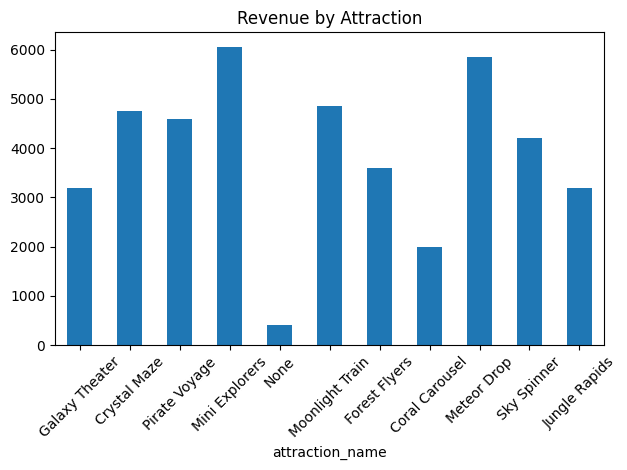

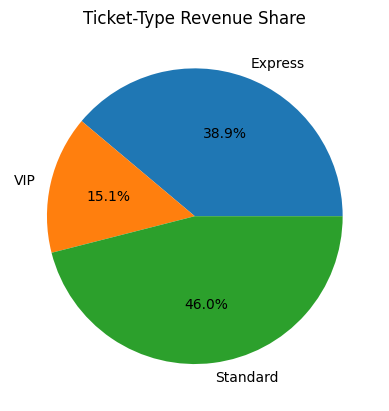

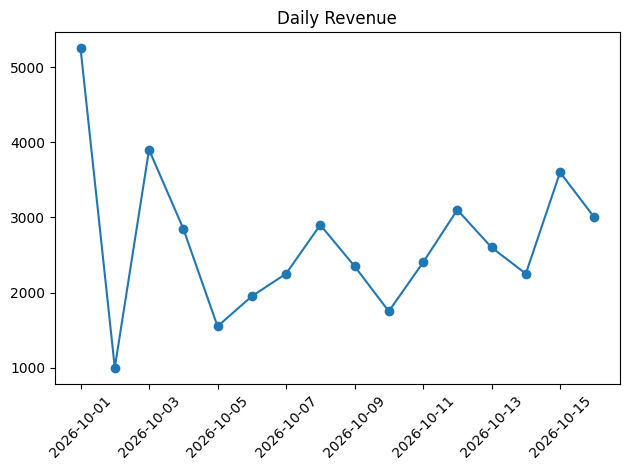

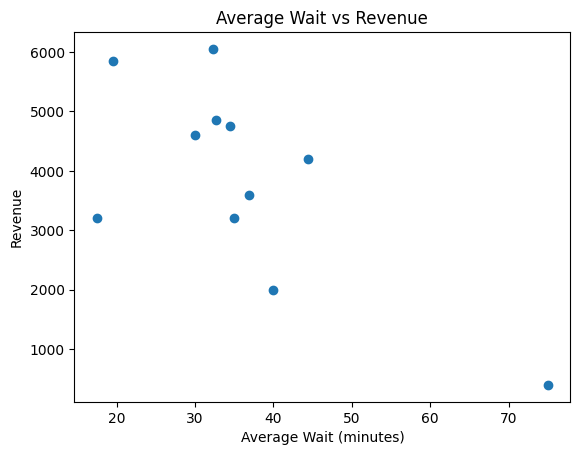

In [ ]:
import matplotlib.pyplot as plt

# Aggregation for visualizations
cap_silver = entries_dedup.filter((F.col('status') == 'Completed') & (F.col('ticket_price') > 0) & (F.col('wait_minutes') >= 0)) \
    .join(attractions, 'attraction_id', 'left') \
    .withColumn('revenue', F.col('ticket_price'))

cap_gold = cap_silver.groupBy('attraction_id', 'attraction_name', 'location.zone') \
    .agg(F.count('*').alias('entries'), F.sum('revenue').alias('revenue'), F.avg('wait_minutes').alias('avg_wait'))

# 1. Bar Chart: Revenue by Attraction
pdf = cap_gold.toPandas()
pdf.plot(kind='bar', x='attraction_name', y='revenue', legend=False, rot=45, title='Revenue by Attraction')
plt.tight_layout()
plt.show()

# 2. Pie Chart: Ticket Type Revenue Share
ticket_pdf = cap_silver.groupBy('ticket_type').agg(F.sum('ticket_price').alias('share')).toPandas()
plt.figure()
plt.pie(ticket_pdf['share'], labels=ticket_pdf['ticket_type'], autopct='%1.1f%%')
plt.title('Ticket-Type Revenue Share')
plt.show()

# 3. Line Chart: Daily Revenue Trend
daily = cap_silver.withColumn('visit_date', F.to_date('visit_date')).groupBy('visit_date').agg(F.sum('revenue').alias('revenue')).orderBy('visit_date').toPandas()
plt.figure()
plt.plot(daily['visit_date'], daily['revenue'], marker='o')
plt.xticks(rotation=45)
plt.title('Daily Revenue')
plt.tight_layout()
plt.show()

# 4. Scatter Plot: Average Wait vs Revenue
scatter = cap_gold.toPandas()
plt.figure()
plt.scatter(scatter['avg_wait'], scatter['revenue'])
plt.xlabel('Average Wait (minutes)')
plt.ylabel('Revenue')
plt.title('Average Wait vs Revenue')
plt.show()
